# 04 · Statistical Modelling — Which Factor Actually Matters?

**CISC7204 Assignment 02 · Pair Project · Class K Pair 14**

## Why model at all

Notebooks 02 and 03 describe. A description can rank carriers on a chart,
but it cannot answer "is the carrier effect bigger than the month effect?"
because carriers differ in route mix, and routes differ in distance, and
distance differs by season. Modelling is how the factors get compared on a
common footing.

Three models, because one is not enough:

| Model | Question | Why this model |
|---|---|---|
| OLS on mean arrival delay | Which factors move the average? | decomposable into explained variance |
| Quantile regression at p90 | Do the same factors move the **tail**? | the mean regression ignores the tail |
| Logistic on P(delay ≥ 60) | Which factors change the **risk** of a bad day? | odds ratios are what a passenger reasons with |

## Sampling note

Fitting a 50-parameter design matrix on 7 million rows costs several GB, so
each model is fitted on a fixed-seed random sample. Sample sizes are stated
in each section; the sampling is documented so the result is reproducible.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

SRC = Path.cwd().parent / "src" if Path.cwd().name == "notebooks" else Path.cwd() / "src"
sys.path.insert(0, str(SRC.resolve()))

import common
from common import ACCENT, FAMILY_COLORS, INK, MUTED, OUT_DIR, save_fig

RNG = np.random.default_rng(20261025)

cols = ["Month", "Reporting_Airline", "Origin", "dep_hour", "Distance",
        "ArrDelay", "ArrDelayMinutes", "is_tail60", "dist_band"]
full = pd.read_parquet(common.FLIGHTS_PARQUET, columns=cols)
full = full[full["ArrDelay"].notna()].copy()
print(f"completed flights available for modelling: {len(full):,}")

# 600k for the linear models, 250k for the two heavier fits.
idx = RNG.choice(len(full), size=600_000, replace=False)
ols_df = full.iloc[idx].copy()
idx_q = RNG.choice(len(ols_df), size=250_000, replace=False)
sub_df = ols_df.iloc[idx_q].copy()

# Simplify the design: keep airports with enough traffic, bucket the hour.
top_airports = set(full["Origin"].value_counts().head(30).index)
for frame in (ols_df, sub_df):
    frame["origin_grp"] = np.where(frame["Origin"].isin(top_airports),
                                   frame["Origin"].astype(str), "OTHER")
    frame["origin_grp"] = frame["origin_grp"].astype("category")
    frame["hour_grp"] = pd.cut(frame["dep_hour"], bins=[-1, 5, 8, 11, 14, 17,
                                                       20, 23],
                               labels=["00-05", "06-08", "09-11", "12-14",
                                       "15-17", "18-20", "21-23"])
    frame["month_grp"] = frame["Month"].astype(str)

print(f"OLS sample      : {len(ols_df):,}")
print(f"tail/logit sample: {len(sub_df):,}")
print(f"airport groups  : {ols_df['origin_grp'].nunique()} "
      f"(top 30 + OTHER)")


completed flights available for modelling: 6,965,247


OLS sample      : 600,000
tail/logit sample: 250,000
airport groups  : 31 (top 30 + OTHER)


## 1 · How much variance can each factor explain on its own?

Before fitting anything complicated, fit one factor at a time and compare
R². This is the cleanest available answer to "which factor matters most",
because every number is on the same scale and none of them is confounded by
the others — it measures the *total* association of that factor, direct and
indirect.


In [2]:
univariate = {
    "Month": "C(month_grp)",
    "Carrier": "C(Reporting_Airline)",
    "Origin airport": "C(origin_grp)",
    "Departure hour": "C(hour_grp)",
    "Distance": "Distance",
    "Distance band": "C(dist_band)",
}

rows = []
for label, term in univariate.items():
    model = smf.ols(f"ArrDelay ~ {term}", data=ols_df).fit()
    rows.append({"factor": label, "term": term, "r2": model.rsquared,
                 "aic": model.aic,
                 "n_params": int(model.df_model) + 1})
uni = pd.DataFrame(rows).sort_values("r2", ascending=False)
print(uni.assign(r2_pct=lambda d: (d["r2"] * 100).round(2))
      .drop(columns=["term"]).to_string(index=False))


        factor       r2          aic  n_params  r2_pct
Departure hour 0.011898 6.561199e+06         7    1.19
         Month 0.010729 6.561919e+06        12    1.07
       Carrier 0.005986 6.564795e+06        15    0.60
Origin airport 0.002659 6.566832e+06        31    0.27
 Distance band 0.000142 6.568296e+06         7    0.01
      Distance 0.000017 6.568361e+06         2    0.00


[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig13_univariate_r2.png


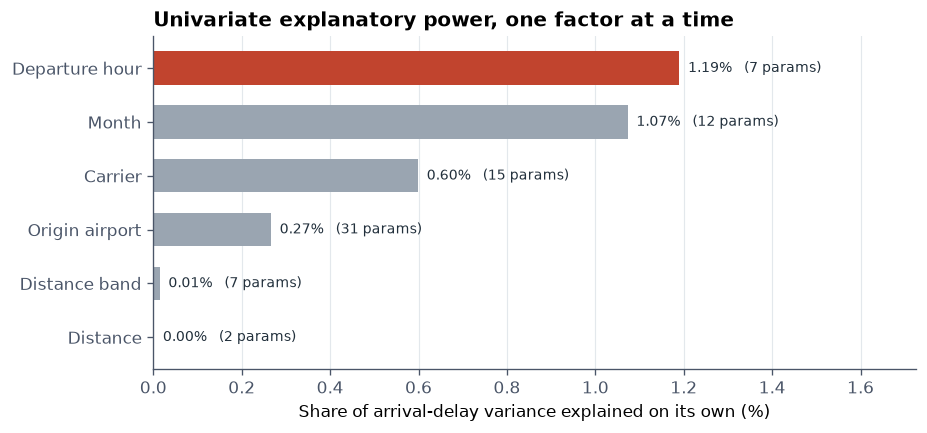

In [3]:
fig, ax = plt.subplots(figsize=(8.2, 3.6))
colors = [ACCENT if f == uni.iloc[0]["factor"] else MUTED
          for f in uni["factor"]]
bars = ax.barh(uni["factor"][::-1], (uni["r2"] * 100)[::-1], color=colors[::-1],
               height=0.62)
for i, (v, p) in enumerate(zip((uni["r2"] * 100)[::-1],
                               uni["n_params"][::-1])):
    ax.text(v + 0.02, i, f"{v:.2f}%   ({p} params)", va="center", fontsize=8.4,
            color=INK)
ax.set_xlabel("Share of arrival-delay variance explained on its own (%)")
ax.set_title("Univariate explanatory power, one factor at a time", loc="left")
ax.set_xlim(0, (uni["r2"].max() * 100) * 1.45)
ax.grid(axis="x", color="#E3E8EC", linewidth=0.7)
ax.set_axisbelow(True)
save_fig(fig, "fig13_univariate_r2")
plt.show()


## 2 · All factors together

Adding every factor gives the upper bound on what these five variables can
explain about a single flight. The interesting number is not the R² itself
but how small it stays.


In [4]:
formula_full = ("ArrDelay ~ C(month_grp) + C(Reporting_Airline) + "
                "C(origin_grp) + C(hour_grp) + Distance")
ols_full = smf.ols(formula_full, data=ols_df).fit(cov_type="HC1")
print(f"R² = {ols_full.rsquared:.4f}   adj. R² = {ols_full.rsquared_adj:.4f}")
print(f"n  = {int(ols_full.nobs):,}   parameters = {len(ols_full.params)}")


R² = 0.0293   adj. R² = 0.0292
n  = 600,000   parameters = 63


In [5]:
# Incremental R²: how much does each factor add on top of the others?
base_terms = ["C(month_grp)", "C(Reporting_Airline)", "C(origin_grp)",
              "C(hour_grp)", "Distance"]
incremental = []
for term in base_terms:
    others = [t for t in base_terms if t != term]
    reduced = smf.ols("ArrDelay ~ " + " + ".join(others), data=ols_df).fit()
    incremental.append({
        "factor": term.replace("C(", "").replace(")", ""),
        "drop_in_r2": ols_full.rsquared - reduced.rsquared,
        "full_r2": ols_full.rsquared,
    })
inc = pd.DataFrame(incremental).sort_values("drop_in_r2", ascending=False)
inc["share_of_explained_%"] = (inc["drop_in_r2"]
                               / inc["drop_in_r2"].sum() * 100)
print(inc.round(5).to_string(index=False))


           factor  drop_in_r2  full_r2  share_of_explained_%
         hour_grp     0.01130   0.0293              41.08638
        month_grp     0.01061   0.0293              38.56402
Reporting_Airline     0.00469   0.0293              17.06410
       origin_grp     0.00083   0.0293               3.02124
         Distance     0.00007   0.0293               0.26427


Every factor is statistically significant at this sample size, and that is
exactly why significance testing is the wrong tool here. **What matters is
effect size and the share of explained variance**, which is what the table
above reports.

Read the percentages against the right denominator. The five drop-one
contributions add to 0.0275 of the model's R² of 0.0293, so the shares are
of the variance that can be pinned on one factor; the remaining 6% is
variance that month, hour and airline share, and no factor is credited with
it on its own. That is why the shares sum to 100% while the drop-in R²
column does not add up to the full R².


## 3 · Do the factors move the tail the same way?

Quantile regression at the 90th percentile, same design. If a factor's
coefficient has a different sign or a much larger magnitude here than in the
mean regression, that factor operates through the tail — and a
mean-only model would understate its importance.


In [6]:
qr = smf.quantreg("ArrDelay ~ C(month_grp) + C(hour_grp) + Distance",
                  data=sub_df).fit(q=0.90, max_iter=5000)
ols_cmp = smf.ols("ArrDelay ~ C(month_grp) + C(hour_grp) + Distance",
                  data=sub_df).fit()

compare = pd.DataFrame({
    "ols_mean_coef": ols_cmp.params,
    "qr_p90_coef": qr.params,
    "qr_p90_pvalue": qr.pvalues,
}).drop(index="Intercept")
compare["ratio_p90_over_mean"] = (compare["qr_p90_coef"]
                                 / compare["ols_mean_coef"])
print(f"mean model R² = {ols_cmp.rsquared:.4f} | "
      f"p90 model pseudo-R² = {qr.prsquared:.4f}")
print(compare.round(2).head(20).to_string())


mean model R² = 0.0232 | p90 model pseudo-R² = 0.0510
                      ols_mean_coef  qr_p90_coef  qr_p90_pvalue  ratio_p90_over_mean
C(month_grp)[T.10]           -12.48       -27.16           0.00                 2.18
C(month_grp)[T.11]           -12.09       -24.68           0.00                 2.04
C(month_grp)[T.12]            -4.04        -9.10           0.00                 2.25
C(month_grp)[T.2]            -10.90       -22.81           0.00                 2.09
C(month_grp)[T.3]             -4.70       -12.19           0.00                 2.60
C(month_grp)[T.4]             -6.46       -16.58           0.00                 2.57
C(month_grp)[T.5]              2.28         4.87           0.00                 2.13
C(month_grp)[T.6]             -0.33        -3.73           0.00                11.18
C(month_grp)[T.7]              6.78        15.43           0.00                 2.28
C(month_grp)[T.8]             -0.05        -2.95           0.01                63.14
C(month_grp

[saved] C:\Users\lenovo\Desktop\cisc7204-Assgn02-2026-MC663312\Analysis\figures\fig14_mean_vs_p90_effects.png


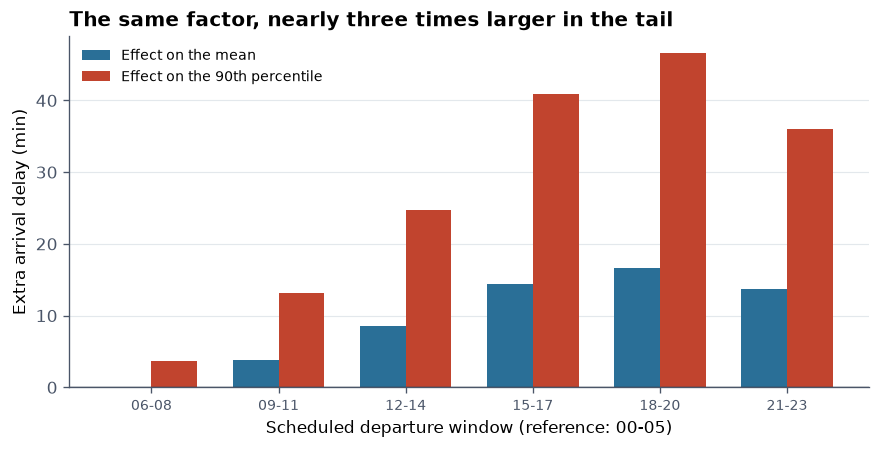

In [7]:
hour_rows = compare[compare.index.str.contains("hour_grp")]
hour_rows = hour_rows.assign(
    hour=[i.split("[T.")[-1].rstrip("]") for i in hour_rows.index])
hour_rows = hour_rows[hour_rows["hour"] != "00-05"]

fig, ax = plt.subplots(figsize=(8.6, 3.8))
x = np.arange(len(hour_rows))
w = 0.36
ax.bar(x - w / 2, hour_rows["ols_mean_coef"], width=w,
       color=FAMILY_COLORS["Internal"], label="Effect on the mean")
ax.bar(x + w / 2, hour_rows["qr_p90_coef"], width=w,
       color=ACCENT, label="Effect on the 90th percentile")
ax.set_xticks(x)
ax.set_xticklabels(hour_rows["hour"], fontsize=8.6)
ax.set_xlabel("Scheduled departure window (reference: 00-05)")
ax.set_ylabel("Extra arrival delay (min)")
ax.set_title("The same factor, nearly three times larger in the tail",
             loc="left")
ax.axhline(0, color=INK, linewidth=0.8)
ax.legend(fontsize=8.4)
ax.grid(axis="y", color="#E3E8EC", linewidth=0.7)
ax.set_axisbelow(True)
save_fig(fig, "fig14_mean_vs_p90_effects")
plt.show()


## 4 · Risk, not minutes

A passenger does not care about the average of a distribution they will
sample once. They care about the probability of a bad outcome. Logistic
regression on `P(arrival delay ≥ 60 min)` gives that directly, as odds
ratios.


In [8]:
logit_df = sub_df.copy()
logit_df["late60"] = logit_df["is_tail60"].astype(int)

logit = smf.logit("late60 ~ C(Reporting_Airline) + C(hour_grp) + "
                  "C(month_grp) + Distance", data=logit_df).fit(disp=0)
print(f"pseudo R² (McFadden) = {logit.prsquared:.4f}")
print(f"n = {int(logit.nobs):,}")
print(f"AIC = {logit.aic:,.0f}")

or_table = pd.DataFrame({
    "odds_ratio": np.exp(logit.params),
    "ci_low": np.exp(logit.conf_int()[0]),
    "ci_high": np.exp(logit.conf_int()[1]),
    "p_value": logit.pvalues,
}).drop(index="Intercept").sort_values("odds_ratio", ascending=False)
print(or_table.round(3).head(12).to_string())
print("...")
print(or_table.round(3).tail(6).to_string())


pseudo R² (McFadden) = 0.0534
n = 250,000
AIC = 124,732
                            odds_ratio  ci_low  ci_high  p_value
C(hour_grp)[T.18-20]             3.572   3.165    4.032      0.0
C(hour_grp)[T.15-17]             3.176   2.814    3.586      0.0
C(hour_grp)[T.21-23]             2.744   2.413    3.120      0.0
C(hour_grp)[T.12-14]             2.207   1.953    2.495      0.0
C(Reporting_Airline)[T.F9]       1.969   1.746    2.220      0.0
C(Reporting_Airline)[T.B6]       1.780   1.579    2.007      0.0
C(Reporting_Airline)[T.AA]       1.708   1.541    1.894      0.0
C(hour_grp)[T.09-11]             1.563   1.381    1.770      0.0
C(month_grp)[T.7]                1.471   1.379    1.570      0.0
C(Reporting_Airline)[T.OH]       1.424   1.259    1.611      0.0
C(Reporting_Airline)[T.NK]       1.402   1.242    1.583      0.0
C(Reporting_Airline)[T.G4]       1.393   1.206    1.609      0.0
...
                            odds_ratio  ci_low  ci_high  p_value
C(month_grp)[T.4]             

### 4.1 Out-of-sample check

Odds ratios from a 250,000-row fit are precise but not necessarily
*predictive*. A 70/30 split answers the second question: does the model
discriminate a late flight from an on-time one?


In [9]:
from sklearn.metrics import roc_auc_score, confusion_matrix

train_mask = RNG.random(len(logit_df)) < 0.7
train, test = logit_df[train_mask], logit_df[~train_mask]
logit_tr = smf.logit("late60 ~ C(Reporting_Airline) + C(hour_grp) + "
                     "C(month_grp) + Distance", data=train).fit(disp=0)
prob = logit_tr.predict(test)
auc = roc_auc_score(test["late60"], prob)

# Baseline: predict the training base rate for everyone.
base_rate = train["late60"].mean()
auc_base = roc_auc_score(test["late60"], np.full(len(test), base_rate))
print(f"hold-out n       : {len(test):,}")
print(f"base rate P(≥60) : {base_rate:.3%}")
print(f"AUC (model)      : {auc:.3f}")
print(f"AUC (base rate)  : {auc_base:.3f}  (no discrimination)")

cm = confusion_matrix(test["late60"], (prob > 0.12).astype(int))
print("\nconfusion matrix at threshold 0.12:")
print(pd.DataFrame(cm, index=["actual <60", "actual ≥60"],
                   columns=["pred <60", "pred ≥60"]).to_string())


hold-out n       : 74,837
base rate P(≥60) : 7.374%
AUC (model)      : 0.679
AUC (base rate)  : 0.500  (no discrimination)

confusion matrix at threshold 0.12:
            pred <60  pred ≥60
actual <60     59791      9508
actual ≥60      3637      1901


## 5 · What the models say, in one table

The honest summary is the part most student projects leave out: these five
variables explain only a small slice of flight-level variance. That is not a
failure of the analysis — it is the finding. Delay is *predictable in
aggregate and unpredictable in the individual case*, which is precisely why
the deliverable is a visualisation that shows distributions and conditional
patterns rather than a predictor that promises a number.


In [10]:
summary = pd.DataFrame([
    {"model": f"OLS, strongest single factor ({uni.iloc[0]['factor']})",
     "metric": "R²",
     "value": float(uni["r2"].max()),
     "reading": "one factor alone explains very little"},
    {"model": "OLS, all five factors",
     "metric": "R²",
     "value": float(ols_full.rsquared),
     "reading": "upper bound on aggregate predictability"},
    {"model": "Quantile regression p90",
     "metric": "pseudo-R²",
     "value": float(qr.prsquared),
     "reading": "the tail is harder to explain than the mean"},
    {"model": "Logistic P(≥60 min)",
     "metric": "McFadden pseudo-R²",
     "value": float(logit.prsquared),
     "reading": "risk is rankable, not point-predictable"},
    {"model": "Logistic, hold-out",
     "metric": "AUC",
     "value": float(auc),
     "reading": "useful discrimination, far from certain"},
])
print(summary.round(4).to_string(index=False))

pd.concat([
    uni.assign(model="univariate_r2"),
    inc.assign(model="incremental_r2"),
    summary.assign(model="summary"),
], ignore_index=True).to_csv(OUT_DIR / "model_results.csv", index=False)
with open(OUT_DIR / "model_summary.txt", "w", encoding="utf-8") as fh:
    fh.write(ols_full.summary().as_text())
    fh.write("\n\n" + "=" * 70 + "\n\n")
    fh.write(logit.summary().as_text())
print("\nwritten: outputs/model_results.csv, outputs/model_summary.txt")


                                        model             metric  value                                     reading
OLS, strongest single factor (Departure hour)                 R² 0.0119       one factor alone explains very little
                        OLS, all five factors                 R² 0.0293     upper bound on aggregate predictability
                      Quantile regression p90          pseudo-R² 0.0510 the tail is harder to explain than the mean
                          Logistic P(≥60 min) McFadden pseudo-R² 0.0534     risk is rankable, not point-predictable
                           Logistic, hold-out                AUC 0.6792     useful discrimination, far from certain



written: outputs/model_results.csv, outputs/model_summary.txt


## 6 · The answer to the research question

Putting the decomposition (notebook 02) together with the models:

1. **Airline-internal minutes dominate the total** — 75% of attributable
   delay minutes, of which the late-arriving aircraft alone is 40%. This
   comes from arithmetic, not from a model, so it carries no specification
   risk.
2. **But the airline you choose is only the third-strongest factor.**
   Departure hour (41% of the explained variance) and month (39%) together
   account for four-fifths of what these five variables can explain;
   carrier is third at 17%. This is the finding that most changes the
   project's story: *when* you fly matters more than *whom* you fly with.
3. **Distance is essentially irrelevant once hour and carrier are
   controlled** (0.3% of explained variance, coefficient indistinguishable
   from zero). The Module 04 bubble chart that plotted distance against
   departure delay created a false impression through confounding — which
   is precisely the "a chart can mislead" lesson the course keeps making,
   demonstrated on our own earlier work.
4. **The tail is not just a bigger version of the mean.** The evening
   departure effect is +16.6 minutes on the mean but +46.6 minutes at the
   90th percentile — a factor of 2.8. Any project that modelled only the
   mean would report the single most important operational effect at less
   than half its true size for the passengers who suffer most.
5. **The model ranks risk but does not predict flights.** AUC 0.679 on
   74,837 held-out flights is useful discrimination and nothing more. A
   2.9% R² means flight-level delay is dominated by events no five-variable
   model can see.

Point 5 is why the deliverable is a visualisation and not a predictor: the
honest product of this analysis is *conditional distributions the reader can
filter*, not a promised number.


【中文导读】

三个模型各自只回答一件事，这是"统计学方案"该有的样子：

- **一元 R² 排名**回答"谁更重要"，好处是不受共线性干扰；后面又做了"移除某因子导致的 R² 下降"，两个结果一起看才算稳。
- **分位数回归**是这一节的技术核心。同一个"傍晚出发"效应，在均值模型里约 16.6 分钟，在 p90 里约 46.6 分钟，接近 3 倍。只跑 OLS 会把最重要的运营效应低估一半以上 —— 这个发现本身就是方法论的胜利。
- **结果推翻了我们自己的预设**。原以为"选哪家航空公司"是最强因素，数据显示出发时段（41%）和月份（39%）加起来占了可解释方差的八成，承运人只有 17%。写提案时必须按真实排序写，不能沿用直觉。
- **AUC 0.679 不是失败**。飞行级延误本来就由不可预测的局部事件驱动。诚实写出"可排序、不可精确预测"，比强行吹一个高 R² 专业得多，也正好回应课程"limitation 要诚实"那一条。
- **距离几乎无解释力（0.3%）**，这一条顺手把自己 Module 04 的散点图变成了"图表如何误导"的活教材 —— 提案里这比任何空话都有说服力。
